# Indian Pre-Owned Car Price Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("12573233-Indian_Car_Market_Capstone_2025_Dataset")

train_df = pd.read_csv(DATA_DIR / "Cap_Training_Data_2025.csv")
test_df = pd.read_csv(DATA_DIR / "Cap_Test_Data_2025.csv")
submission_df = pd.read_csv(DATA_DIR / "Cap_Sample_Submission_2025.csv")

print("Training dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)
print("Sample submission shape:", submission_df.shape)

Training dataset shape: (53515, 17)
Test dataset shape: (5615, 16)
Sample submission shape: (5615, 2)


## 2. Exploratory Data Analysis (EDA)

In [3]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nSample submission columns:")
print(submission_df.columns.tolist())

Training columns:
['ID', 'Maker', 'model', 'Location', 'Distance ', 'Owner Type', 'manufacture_year', 'Age of car', 'engine_displacement', 'engine_power', 'body_type', 'Vroom Audit Rating', 'transmission', 'door_count', 'seat_count', 'fuel_type', 'Price']

Test columns:
['ID', 'Maker', 'model', 'Location', 'Distance ', 'Owner Type', 'manufacture_year', 'Age of car', 'engine_displacement', 'engine_power', 'body_type', 'Vroom Audit Rating', 'transmission', 'door_count', 'seat_count', 'fuel_type']

Sample submission columns:
['ID', 'Price']


In [4]:
train_df.head()

,ID,Maker,model,Location,Distance,Owner Type,manufacture_year,Age of car,engine_displacement,engine_power,body_type,Vroom Audit Rating,transmission,door_count,seat_count,fuel_type,Price
0,11100001,skoda,octavia,Ahmedabad,NaN,Second,1973.0,52,1964,147.0,compact,8,man,NaN,NaN,petrol,543764.25
1,11100002,fiat,panda,Ahmedabad,27750.0,Third,2021.0,4,1242,51.0,NaN,6,man,4.0,4.0,petrol,401819.25
2,11100003,bmw,x1,Hyderabad,46000.0,Third,2023.0,2,1995,105.0,NaN,7,auto,4.0,5.0,diesel,2392855.50
3,11100004,nissan,juke,Mumbai,43949.0,Third,2020.0,5,1618,140.0,NaN,7,man,4.0,5.0,petrol,958606.50
4,11100005,bmw,x5,Jaipur,59524.0,Fourth & Above,2021.0,4,2993,180.0,NaN,7,auto,4.0,5.0,diesel,3085561.50


In [5]:
train_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 53515 entries, 0 to 53514
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   53515 non-null  int64  
 1   Maker                53515 non-null  str    
 2   model                53515 non-null  str    
 3   Location             53509 non-null  str    
 4   Distance             52304 non-null  float64
 5   Owner Type           53515 non-null  str    
 6   manufacture_year     53513 non-null  float64
 7   Age of car           53515 non-null  int64  
 8   engine_displacement  53515 non-null  int64  
 9   engine_power         52076 non-null  float64
 10  body_type            4136 non-null   str    
 11  Vroom Audit Rating   53515 non-null  int64  
 12  transmission         53515 non-null  str    
 13  door_count           45981 non-null  float64
 14  seat_count           45004 non-null  float64
 15  fuel_type            53515 non-null  str    
 1

In [6]:
train_df.isnull().sum()


ID                         0
Maker                      0
model                      0
Location                   6
Distance                1211
Owner Type                 0
manufacture_year           2
Age of car                 0
engine_displacement        0
engine_power            1439
body_type              49379
Vroom Audit Rating         0
transmission               0
door_count              7534
seat_count              8511
fuel_type                  0
Price                      0
dtype: int64

In [7]:
print("Duplicate rows:", train_df.duplicated().sum())

Duplicate rows: 0


## Price distribution and outliers

In [8]:
train_df["Price"].describe()

count    5.351500e+04
mean     1.098084e+06
std      8.441565e+05
min      3.000000e+00
25%      5.051812e+05
50%      8.854552e+05
75%      1.477829e+06
max      2.212078e+07
Name: Price, dtype: float64

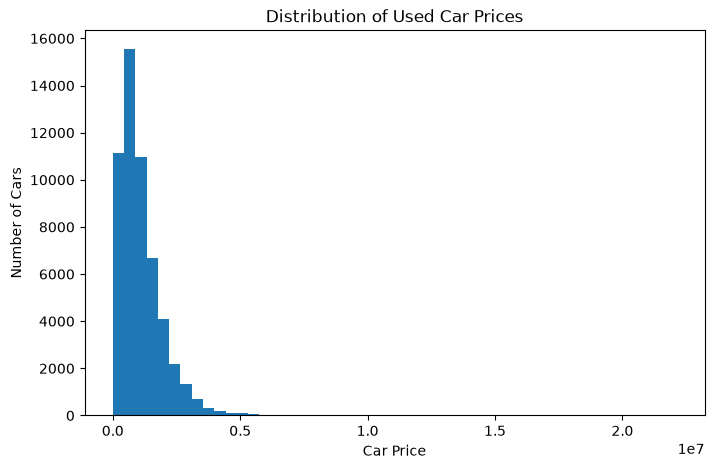

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(train_df["Price"], bins=50)
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Used Car Prices")
plt.show()


In [10]:
print("Lowest 10 prices:")
print(train_df["Price"].nsmallest(10))

print("\nHighest 10 prices:")
print(train_df["Price"].nlargest(10))

Lowest 10 prices:
10704    3.00
13439    3.00
17572    3.00
24594    3.00
26130    3.00
32500    3.00
46226    3.00
19564    3.75
5998     5.25
18274    5.25
Name: Price, dtype: float64

Highest 10 prices:
37535    22120775.25
50088    15747432.75
177      12755662.50
3959     10503108.75
29172     9749811.00
12834     9188859.75
46139     9001257.75
40604     8820488.25
6585      8760546.75
25464     8429430.75
Name: Price, dtype: float64


In [11]:
train_df.loc[
    train_df["Price"] <= 5.25,
    ["Maker", "model", "Location", "Price"]
]

,Maker,model,Location,Price
5998,skoda,octavia,Hyderabad,5.25
10704,skoda,superb,Chennai,3.00
13439,skoda,octavia,Kochi,3.00
17572,skoda,superb,Bangalore,3.00
18274,skoda,octavia,Delhi,5.25
19564,toyota,auris,Chennai,3.75
24594,skoda,octavia,Kochi,3.00
26130,skoda,octavia,Chennai,3.00
30338,skoda,octavia,Mumbai,5.25
32360,toyota,avensis,Coimbatore,5.25


In [12]:
missing_percent = (train_df.isnull().sum() / len(train_df)) * 100

missing_percent.sort_values(ascending=False).round(2)

body_type              92.27
seat_count             15.90
door_count             14.08
engine_power            2.69
Distance                2.26
Location                0.01
manufacture_year        0.00
ID                      0.00
model                   0.00
engine_displacement     0.00
Age of car              0.00
Owner Type              0.00
Maker                   0.00
transmission            0.00
Vroom Audit Rating      0.00
fuel_type               0.00
Price                   0.00
dtype: float64

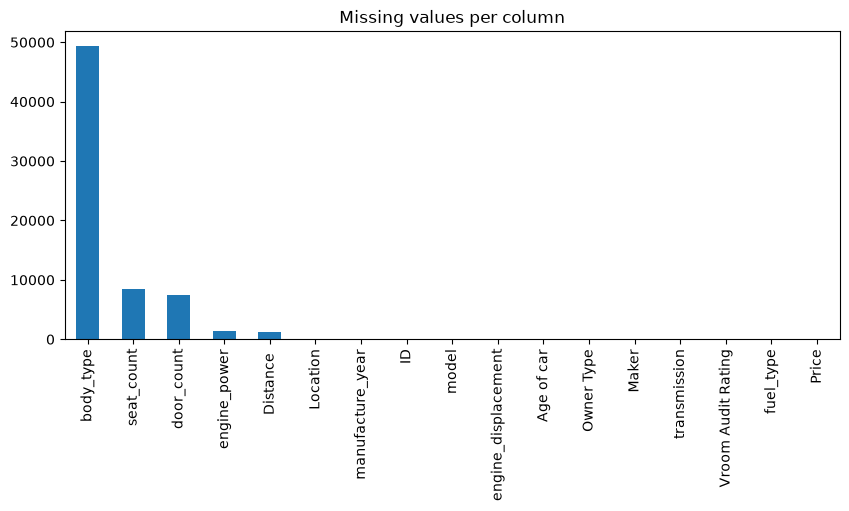

In [13]:
# Bar chart of missing values per column
train_df.isnull().sum().sort_values(ascending=False).plot(kind="bar", figsize=(10, 4))
plt.title("Missing values per column")
plt.show()

In [14]:
train_df.describe()

,ID,Distance,manufacture_year,Age of car,engine_displacement,engine_power,Vroom Audit Rating,door_count,seat_count,Price
count,5.351500e+04,5.230400e+04,53513.000000,53515.000000,53515.000000,52076.000000,53515.000000,45981.000000,45004.000000,5.351500e+04
mean,1.112676e+07,9.454626e+04,2019.408032,5.591946,1904.049014,100.448345,5.998374,3.973011,4.886099,1.098084e+06
std,1.544859e+04,2.755617e+05,4.650367,4.650281,1496.564596,45.330622,1.418336,0.740659,0.564332,8.441565e+05
min,1.110000e+07,0.000000e+00,1943.000000,0.000000,14.000000,10.000000,4.000000,1.000000,1.000000,3.000000e+00
25%,1.111338e+07,1.549000e+04,2017.000000,2.000000,1395.000000,73.000000,5.000000,4.000000,5.000000,5.051812e+05
50%,1.112676e+07,6.552000e+04,2020.000000,5.000000,1896.000000,91.000000,6.000000,4.000000,5.000000,8.854552e+05
75%,1.114014e+07,1.356410e+05,2023.000000,8.000000,1995.000000,125.000000,7.000000,4.000000,5.000000,1.477829e+06
max,1.115352e+07,9.899800e+06,2025.000000,82.000000,32000.000000,896.000000,8.000000,6.000000,9.000000,2.212078e+07


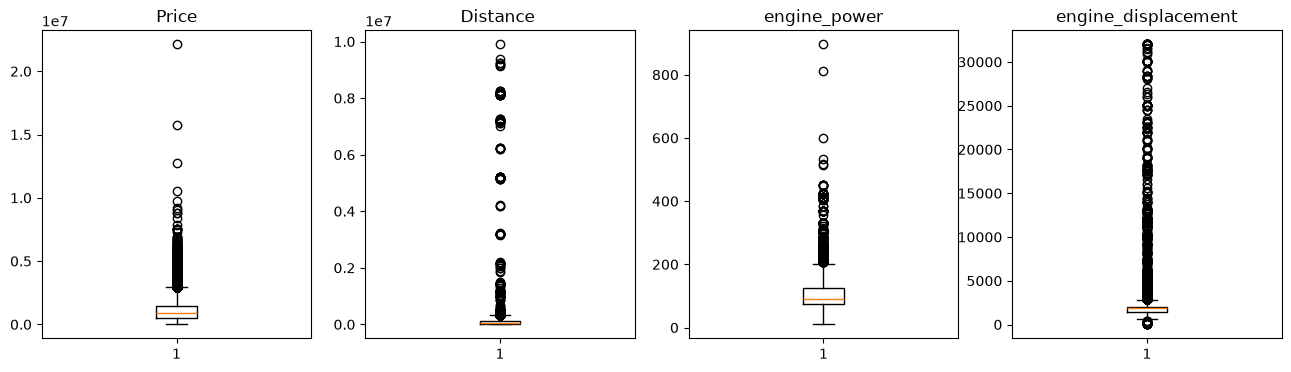

In [15]:
# Boxplots to detect outliers in numeric features
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, col in zip(ax, ["Price", "Distance ", "engine_power", "engine_displacement"]):
    a.boxplot(train_df[col].dropna())
    a.set_title(col)
plt.show()

### Distance, age and year checks

In [16]:
train_df.nlargest(10, "Distance ")[
    ["Maker", "model", "Distance ", "manufacture_year", "Age of car", "Price"]
]

,Maker,model,Distance,manufacture_year,Age of car,Price
25246,skoda,citigo,9899800.0,2023.0,2,496854.0
29544,skoda,octavia,9370350.0,2018.0,7,466321.5
5923,skoda,superb,9235000.0,2018.0,7,680052.0
36758,skoda,superb,9235000.0,2018.0,7,680052.0
42083,skoda,superb,9175000.0,2018.0,7,829941.0
48410,skoda,roomster,9163000.0,2018.0,7,358068.0
24015,skoda,superb,9136000.0,2018.0,7,749167.5
33656,skoda,octavia,8258200.0,2017.0,8,402480.0
39648,skoda,superb,8235928.0,2017.0,8,663397.5
53185,skoda,superb,8234928.0,2017.0,8,691155.0


In [17]:
train_df[["manufacture_year", "Age of car"]].head(10)

,manufacture_year,Age of car
0,1973.0,52
1,2021.0,4
2,2023.0,2
3,2020.0,5
4,2021.0,4
5,2024.0,1
6,2018.0,7
7,NaN,5
8,NaN,5
9,2019.0,6


In [18]:
year_sum = train_df["manufacture_year"] + train_df["Age of car"]

year_sum.value_counts().sort_index()

2025.0    53513
Name: count, dtype: int64

### Categorical features

In [19]:
train_df["Maker"].value_counts().head(10)


Maker
skoda       21563
toyota       7840
audi         7326
bmw          7178
nissan       5485
hyundai      2240
fiat         1845
maserati       38
Name: count, dtype: int64

In [20]:
train_df["fuel_type"].value_counts()

fuel_type
diesel    27559
petrol    25956
Name: count, dtype: int64

In [21]:
train_df["Location"].value_counts().head(10)

Location
Coimbatore    4974
Kochi         4969
Bangalore     4877
Jaipur        4870
Kolkata       4867
Pune          4862
Mumbai        4860
Chennai       4834
Delhi         4822
Hyderabad     4804
Name: count, dtype: int64

In [22]:
train_df["transmission"].value_counts()

transmission
man     36734
auto    16781
Name: count, dtype: int64

In [23]:
train_df["Owner Type"].value_counts()

Owner Type
First             13406
Third             13395
Second            13365
Fourth & Above    13349
Name: count, dtype: int64

In [24]:
train_df["body_type"].value_counts()

body_type
compact    4127
van           9
Name: count, dtype: int64

In [25]:
print("Number of unique car models:", train_df["model"].nunique())

Number of unique car models: 23


### Engine features

In [26]:
train_df["engine_displacement"].describe()

count    53515.000000
mean      1904.049014
std       1496.564596
min         14.000000
25%       1395.000000
50%       1896.000000
75%       1995.000000
max      32000.000000
Name: engine_displacement, dtype: float64

In [27]:
train_df.nlargest(5, "engine_displacement")[
    ["Maker", "model", "engine_displacement", "engine_power", "Price"]
]

,Maker,model,engine_displacement,engine_power,Price
1090,bmw,x3,32000,135.0,1662657.00
4196,bmw,x3,32000,NaN,402480.00
5515,bmw,x3,32000,110.0,582901.50
8153,bmw,x3,32000,NaN,369171.00
10415,bmw,x3,32000,NaN,660621.75


In [28]:
train_df.nsmallest(5, "engine_displacement")[
    ["Maker", "model", "engine_displacement", "engine_power", "Price"]
]

,Maker,model,engine_displacement,engine_power,Price
36822,hyundai,i30,14,74.0,944913.75
23606,toyota,aygo,69,50.0,376587.75
21035,toyota,auris,73,73.0,1833347.25
52120,skoda,octavia,74,896.0,430236.75
1899,skoda,octavia,77,77.0,491302.50


In [29]:
train_df["engine_power"].describe()

count    52076.000000
mean       100.448345
std         45.330622
min         10.000000
25%         73.000000
50%         91.000000
75%        125.000000
max        896.000000
Name: engine_power, dtype: float64

In [30]:
train_df.nlargest(5, "engine_power")[
    ["Maker", "model", "engine_displacement", "engine_power", "Price"]
]

,Maker,model,engine_displacement,engine_power,Price
52120,skoda,octavia,74,896.0,430236.75
24176,hyundai,i30,1000,812.0,887953.50
17054,hyundai,i30,1591,599.0,887953.50
25956,audi,tt,3993,533.0,6746749.50
32384,audi,tt,4991,516.0,2474616.75


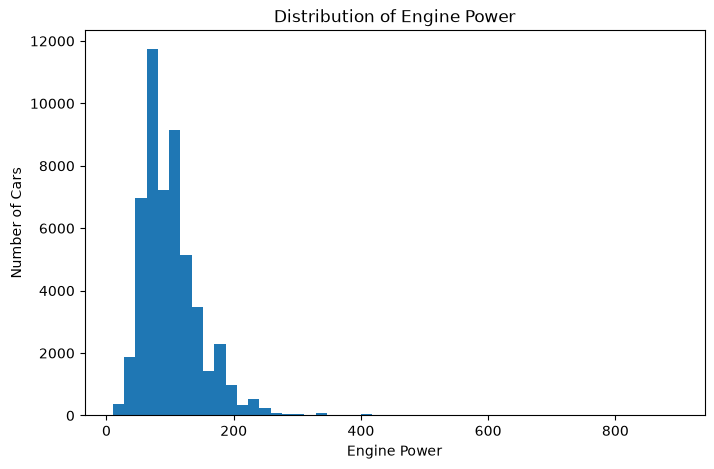

In [31]:
plt.figure(figsize=(8, 5))
plt.hist(train_df["engine_power"].dropna(), bins=50)
plt.xlabel("Engine Power")
plt.ylabel("Number of Cars")
plt.title("Distribution of Engine Power")
plt.show()

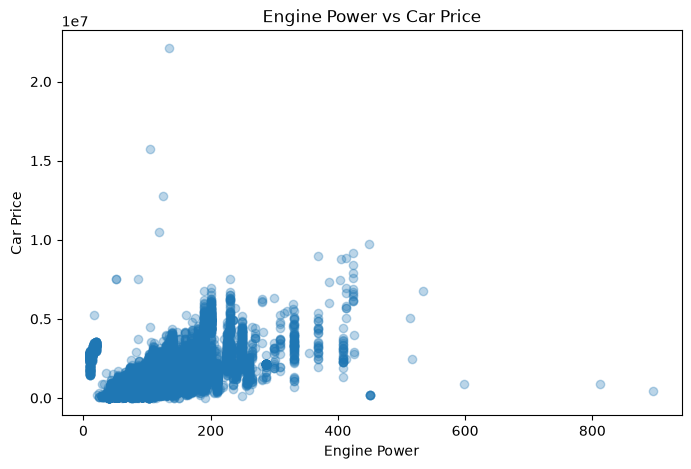

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter(train_df["engine_power"], train_df["Price"], alpha=0.3)
plt.xlabel("Engine Power")
plt.ylabel("Car Price")
plt.title("Engine Power vs Car Price")
plt.show()

### Correlation with price

In [33]:
train_df["engine_power"].corr(train_df["Price"])

np.float64(0.627944189152445)

In [34]:
train_df["Age of car"].corr(train_df["Price"])

np.float64(-0.5067027687084862)

In [35]:
train_df["Distance "].corr(train_df["Price"])

np.float64(-0.1585149802015455)

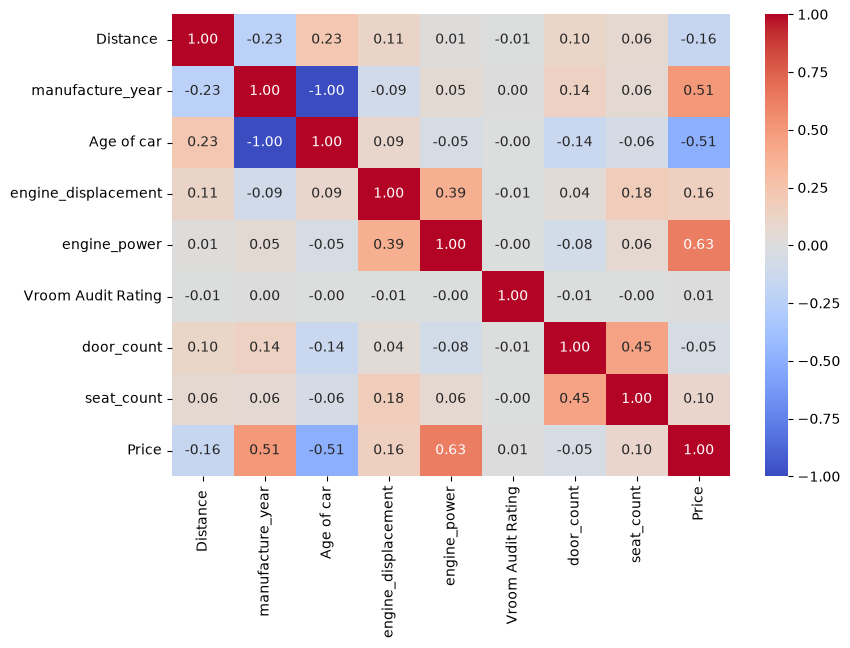

In [36]:
# Correlation heatmap of numeric features
plt.figure(figsize=(9, 6))
sns.heatmap(train_df.select_dtypes(include="number").drop(columns=["ID"]).corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

### Price by category, age and distance

In [37]:
train_df.groupby("fuel_type")["Price"].median()

fuel_type
diesel    1193205.0
petrol     675300.0
Name: Price, dtype: float64

In [38]:
train_df.groupby("Owner Type")["Price"].median().sort_values(ascending=False)


Owner Type
Third             901776.75
First             885455.25
Fourth & Above    885455.25
Second            871576.50
Name: Price, dtype: float64

In [39]:
train_df.groupby("transmission")["Price"].median()

transmission
auto    1572682.50
man      705860.25
Name: Price, dtype: float64

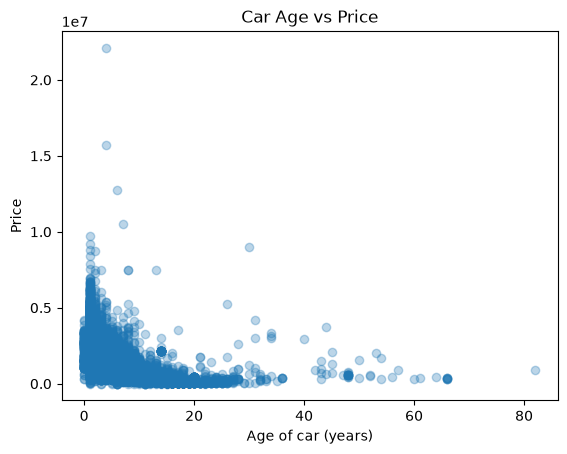

In [40]:
import matplotlib.pyplot as plt

plt.scatter(train_df["Age of car"], train_df["Price"], alpha=0.3)
plt.xlabel("Age of car (years)")
plt.ylabel("Price")
plt.title("Car Age vs Price")
plt.show()

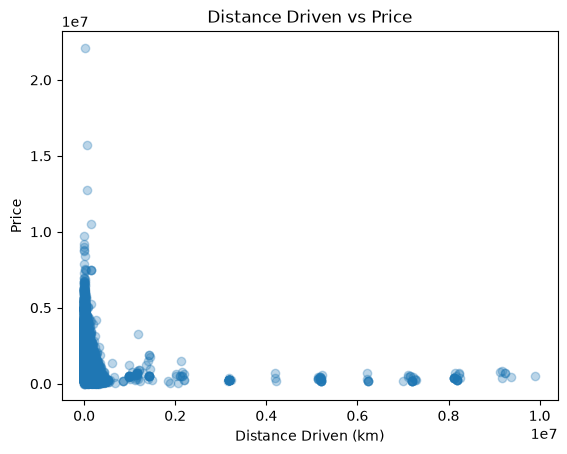

In [41]:
plt.scatter(train_df["Distance "], train_df["Price"], alpha=0.3)
plt.xlabel("Distance Driven (km)")
plt.ylabel("Price")
plt.title("Distance Driven vs Price")
plt.show()

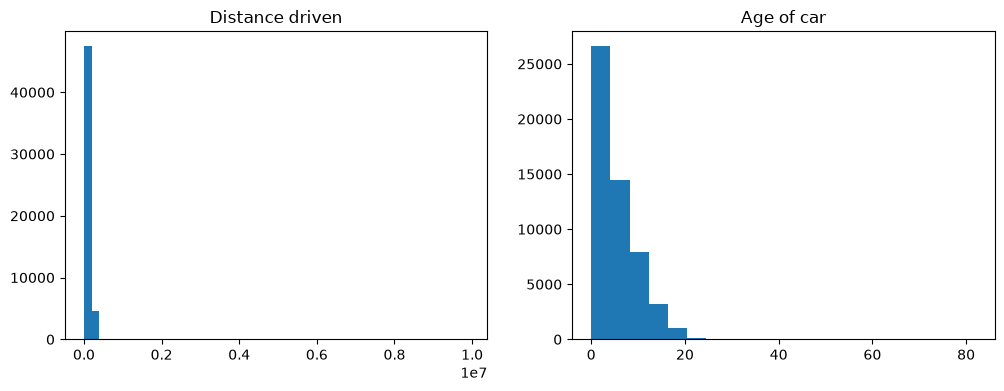

In [42]:
# Distribution of distance driven and age of car
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(train_df["Distance "].dropna(), bins=50); ax[0].set_title("Distance driven")
ax[1].hist(train_df["Age of car"], bins=20); ax[1].set_title("Age of car")
plt.show()

### Final data checks (duplicate IDs, data types, test missing values)

In [43]:
print("Duplicate training IDs:", train_df["ID"].duplicated().sum())
print("Duplicate test IDs:", test_df["ID"].duplicated().sum())

Duplicate training IDs: 0
Duplicate test IDs: 0


In [44]:
train_df.dtypes

ID                       int64
Maker                      str
model                      str
Location                   str
Distance               float64
Owner Type                 str
manufacture_year       float64
Age of car               int64
engine_displacement      int64
engine_power           float64
body_type                  str
Vroom Audit Rating       int64
transmission               str
door_count             float64
seat_count             float64
fuel_type                  str
Price                  float64
dtype: object

In [45]:
test_df.isnull().sum().sort_values(ascending=False)

body_type              5193
seat_count              891
door_count              806
engine_power            168
Distance                128
ID                        0
model                     0
Maker                     0
Age of car                0
manufacture_year          0
Owner Type                0
Location                  0
Vroom Audit Rating        0
engine_displacement       0
transmission              0
fuel_type                 0
dtype: int64

## 3. Data Preprocessing

In [46]:
X = train_df.drop(
    columns=["Price", "ID", "body_type", "manufacture_year"]
)
y = train_df["Price"]

In [47]:
from sklearn.model_selection import train_test_split

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train_raw.shape)
print("Validation data:", X_val_raw.shape)

Training data: (42812, 13)
Validation data: (10703, 13)


In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_cols = X_train_raw.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train_raw.select_dtypes(include=["object", "str"]).columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))

Numerical columns: 7
Categorical columns: 6


In [49]:
X_train_processed = preprocessor.fit_transform(X_train_raw)

X_val_processed = preprocessor.transform(X_val_raw)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

Training shape: (42812, 57)
Validation shape: (10703, 57)


## 4. Model building

In [50]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Model training completed!")

Model training completed!


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = rf_model.predict(X_val_processed)

mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 108180.3194886105
RMSE: 202235.21506457057
R² Score: 0.9425304506506158


In [52]:
comparison = pd.DataFrame({
    "Actual Price": y_val.values,
    "Predicted Price": y_pred
})

comparison["Absolute Error"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
).abs()

comparison.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

,Actual Price,Predicted Price,Absolute Error
5397,7504366.50,2.907258e+05,7.213641e+06
2115,9001257.75,3.693721e+06,5.307537e+06
6178,5250702.00,1.020536e+06,4.230166e+06
300,1088263.50,3.498593e+06,2.410330e+06
3606,2104371.75,4.489392e+06,2.385020e+06
2743,814952.25,3.174472e+06,2.359520e+06
7880,2205249.75,4.518585e+06,2.313335e+06
7363,8760546.75,6.602157e+06,2.158390e+06
8153,1633098.75,3.411258e+06,1.778159e+06
1467,3375999.00,1.724182e+06,1.651817e+06


### Error analysis

In [53]:
error_position = comparison["Absolute Error"].to_numpy().argmax()

print("Actual price:", comparison.iloc[error_position]["Actual Price"])
print("Predicted price:", comparison.iloc[error_position]["Predicted Price"])

print("\nCar details:")
display(X_val_raw.iloc[error_position].to_frame().T)

Actual price: 7504366.5
Predicted price: 290725.7925

Car details:


,Maker,model,Location,Distance,Owner Type,Age of car,engine_displacement,engine_power,Vroom Audit Rating,transmission,door_count,seat_count,fuel_type
43667,skoda,roomster,Chennai,158000.0,First,8,1198,51.0,6,man,4.0,5.0,petrol


In [54]:
Q1 = train_df["Price"].quantile(0.25)
Q3 = train_df["Price"].quantile(0.75)

IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Prices above upper limit:", (train_df["Price"] > upper_limit).sum())
print("Prices below lower limit:", (train_df["Price"] < lower_limit).sum())

Lower limit: -953790.1875
Upper limit: 2936800.3125
Prices above upper limit: 1948
Prices below lower limit: 0


In [55]:
high_price_cars = train_df[train_df["Price"] > upper_limit]

print("High-priced records by manufacturer:")
display(high_price_cars["Maker"].value_counts())

print("\nHigh-priced records by model:")
display(high_price_cars["model"].value_counts().head(10))

High-priced records by manufacturer:


Maker
audi      1179
bmw        739
skoda       26
toyota       3
fiat         1
Name: count, dtype: int64


High-priced records by model:


model
q7         481
x5         343
x3         337
q5         290
coupe      220
tt         100
q3          89
x1          59
superb      23
octavia      2
Name: count, dtype: int64

In [56]:
results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Value": [mae, rmse, r2]
})

display(results)


,Metric,Value
0,MAE,108180.319489
1,RMSE,202235.215065
2,R² Score,0.942530


### Baseline and simple models

In [57]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train_processed, y_train)

baseline_predictions = baseline_model.predict(X_val_processed)

print("Baseline MAE:", mean_absolute_error(y_val, baseline_predictions))
print("Baseline RMSE:", np.sqrt(mean_squared_error(y_val, baseline_predictions)))
print("Baseline R2:", r2_score(y_val, baseline_predictions))

Baseline MAE: 627030.304106213
Baseline RMSE: 843683.7864072346
Baseline R2: -0.00019259605421928505


In [58]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train_processed, y_train)

lr_predictions = lr_model.predict(X_val_processed)

print("Linear Regression MAE:",
      mean_absolute_error(y_val, lr_predictions))

print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_val, lr_predictions)))

print("Linear Regression R2:",
      r2_score(y_val, lr_predictions))

Linear Regression MAE: 263546.27693910437
Linear Regression RMSE: 430756.52402461646
Linear Regression R2: 0.7392718298093521


In [59]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train_processed, y_train)

dt_predictions = dt_model.predict(X_val_processed)

print("Decision Tree MAE:",
      mean_absolute_error(y_val, dt_predictions))

print("Decision Tree RMSE:",
      np.sqrt(mean_squared_error(y_val, dt_predictions)))

print("Decision Tree R2:",
      r2_score(y_val, dt_predictions))

Decision Tree MAE: 141798.46640544708
Decision Tree RMSE: 290261.01385838486
Decision Tree R2: 0.8816136461749464


### XGBoost

In [60]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

xgb_predictions = xgb_model.predict(X_val_processed)

print("XGBoost MAE:",
      mean_absolute_error(y_val, xgb_predictions))

print("XGBoost RMSE:",
      np.sqrt(mean_squared_error(y_val, xgb_predictions)))

print("XGBoost R2:",
      r2_score(y_val, xgb_predictions))


XGBoost MAE: 113054.75469458038
XGBoost RMSE: 197930.7362860913
XGBoost R2: 0.9449508383301379


## Cross-validation and hyperparameter tuning

In [61]:
from sklearn.model_selection import cross_val_score

rf_cv_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

cv_scores = cross_val_score(
    rf_cv_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

print("MAE for each fold:", -cv_scores)
print("Average CV MAE:", (-cv_scores).mean())
print("Standard deviation:", (-cv_scores).std())

MAE for each fold: [113370.07070515 114138.87540617 106540.62764905 110965.82200428
 107404.77076825]
Average CV MAE: 110484.0333065802
Standard deviation: 3064.35993146503


### Random Forest tuning

In [62]:
import time
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# convert sparse -> dense (only ~20 MB at this size)
X_dense = X_train_processed.toarray()

# quick baseline timing first
t = time.time()
RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42).fit(X_dense, y_train)
print("One fit took:", round(time.time() - t, 1), "seconds")

One fit took: 23.3 seconds


In [63]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 15, 25],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=1),  # inner: no parallelism
    param_distributions=param_grid,
    n_iter=8,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,       # outer: parallel
    verbose=2
)

random_search.fit(X_dense, y_train)

print("Best parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 15}
Best CV MAE: 111122.00309982184


### Check the target for invalid prices

In [64]:
print(y_train.describe())

count    4.281200e+04
mean     1.095742e+06
std      8.442787e+05
min      3.000000e+00
25%      5.038298e+05
50%      8.854552e+05
75%      1.475365e+06
max      2.212078e+07
Name: Price, dtype: float64


In [65]:
print((y_train < 50000).sum())
print(y_train[y_train < 50000].head())

117
47401    48575.25
14203    36084.75
18622    48758.25
6404      1107.75
643      26253.00
Name: Price, dtype: float64


In [66]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


## Model comparison (RMSE, MAE, R²)

In [67]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# convert sparse data to dense
X_dense = X_train_processed.toarray()

# remove the 117 rows with absurd prices (data errors)
mask = (y_train >= 50000).values
X_clean, y_clean = X_dense[mask], y_train[mask]

# split into training and validation parts
X_tr, X_val, y_tr, y_val = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

# the models to compare
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": random_search.best_estimator_,
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1),
}

# train each model and measure its errors
results = []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_val)
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "MAE": mean_absolute_error(y_val, pred),
        "R2": r2_score(y_val, pred),
    })

pd.DataFrame(results).sort_values("RMSE")

,Model,RMSE,MAE,R2
2,XGBoost,180945.246486,111987.633698,0.951736
3,LightGBM,181926.411909,112939.387636,0.951211
1,Random Forest,194294.698104,110180.800694,0.944351
0,Linear Regression,412459.925105,256307.967335,0.749218


## XGBoost tuning

In [68]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [300, 500, 800],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [4, 6, 8, 10],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}

xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=1),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=2,
)
xgb_search.fit(X_tr, y_tr)

print("Best parameters:", xgb_search.best_params_)
print("Best CV MAE:", -xgb_search.best_score_)

# check on the validation set
best_xgb = xgb_search.best_estimator_
pred = best_xgb.predict(X_val)
print("Val RMSE:", np.sqrt(mean_squared_error(y_val, pred)))
print("Val MAE:", mean_absolute_error(y_val, pred))
print("Val R2:", r2_score(y_val, pred))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.85}
Best CV MAE: 113177.99643112028
Val RMSE: 190295.36235254328
Val MAE: 108960.65218226665
Val R2: 0.9466186324503055


## Log-price target (final improvement)

In [69]:
# train on log(price), then convert predictions back to rupees
best_params = xgb_search.best_params_

xgb_log = XGBRegressor(**best_params, random_state=42, n_jobs=-1)
xgb_log.fit(X_tr, np.log1p(y_tr))

pred_log = np.expm1(xgb_log.predict(X_val))

print("Log model RMSE:", np.sqrt(mean_squared_error(y_val, pred_log)))
print("Log model MAE:", mean_absolute_error(y_val, pred_log))
print("Log model R2:", r2_score(y_val, pred_log))

Log model RMSE: 178800.4575183493
Log model MAE: 106623.73107808657
Log model R2: 0.9528729192665552


## Save the final model

In [70]:
import joblib

# final model: best XGBoost params, log price, trained on ALL cleaned data
final_model = XGBRegressor(**xgb_search.best_params_, random_state=42, n_jobs=-1)
final_model.fit(X_clean, np.log1p(y_clean))

# save the model
joblib.dump(final_model, "car_price_model.joblib")

# save your preprocessing (use YOUR variable name for the preprocessor)
joblib.dump(preprocessor, "preprocessor.joblib")

print("Saved!")

Saved!


## Predict test data and create the submission file

In [71]:
print(preprocessor)
print(getattr(preprocessor, "feature_names_in_", "no feature_names_in_"))

try:
    X_test_processed = preprocessor.transform(test_df)
    print("Worked! Shape:", X_test_processed.shape)
except Exception as e:
    print("Error:", e)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Distance ', 'Age of car',
                                  'engine_displacement', 'engine_power',
                                  'Vroom Audit Rating', 'door_count',
                                  'seat_count']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Maker', 'model', 'Location', 'Owner Type',
                                  'transmission', 'fue

In [72]:
X_test_dense = X_test_processed.toarray()
preds = np.expm1(final_model.predict(X_test_dense))   # model predicts log price, so convert back

sample = pd.read_csv("12573233-Indian_Car_Market_Capstone_2025_Dataset/Cap_Sample_Submission_2025.csv")
submission = pd.DataFrame({"ID": test_df["ID"], "Price": preds})
submission.to_csv("my_submission.csv", index=False)

print(submission.shape, sample.shape)
print(submission.columns.tolist(), sample.columns.tolist())
print(submission["Price"].describe())

(5615, 2) (5615, 2)
['ID', 'Price'] ['ID', 'Price']
count    5.615000e+03
mean     1.086156e+06
std      8.094486e+05
min      5.939202e+04
25%      5.114691e+05
50%      8.812968e+05
75%      1.466575e+06
max      8.195290e+06
Name: Price, dtype: float64


## Conclusion

**Goal:** predict the price of a pre-owned car in India from its features such as maker, model, location, distance driven, age, engine details and fuel type.

**What was done**
- Explored the data and removed rows with impossible prices.
- Filled missing values, scaled numeric features and encoded categorical features in one reusable pipeline.
- Compared a baseline, Linear Regression, Decision Tree, Random Forest, XGBoost and LightGBM, and tuned the best models with cross-validation.

**Findings**
- Tree-based models clearly beat Linear Regression and the baseline.
- XGBoost, tuned and trained on the log of the price, gave the best result on RMSE, MAE and R². The log helps because car prices are heavily skewed.
- The final model is used in the Streamlit app, which gives a price estimate with a fair price range, batch predictions and trend charts.

**Limitations:** the model is less accurate for rare, very expensive cars because there are few examples of them, and `body_type` was not used because most of its values are missing.